# 07 · Inference-time experiments: test-time resolution and tiling

Part of *Your pipeline*. The weakest part of every model is small objects (`rtdetr_nq500_960`:
AP_small 0.086 vs AP_large 0.41), and input resolution was the strongest factor in training
(YOLO 640 → 1024 px: +53 % mAP, RT-DETR 640 → 960 px: +23 %), while a longer schedule did not help
(`rtdetr_nq500_960_s10`: validation mAP flat after epoch 7). The ideas below enlarge the objects
**at inference only**, with the already trained fold models:

| variant | what changes | hypothesis |
|---|---|---|
| `*_full` | nothing (reference, training resolution) | |
| `*_i1152`, `*_i1280` | the whole frame at a larger input size than in training | more pixels per object; may hurt if the scale shift from training is too large |
| `*_tiles` | 2 × 2 overlapping tiles (each 60 % of the frame side), every tile at the training input size; boxes cut by an inner tile border are dropped, the rest merged by class-wise NMS | objects are 1.67× larger for the model (slicing-aided inference, Akyon et al. 2022); large objects are left to the full-frame prediction when both are fused in `06_ensemble` |
| `*_tiles3` | 3 × 3 tiles (each 40 % of the frame side) | objects 2.5× larger: helps the smallest objects further, or the scale shift from training becomes too large |

Protocol: every variant is evaluated out-of-fold on the same frames as all other experiments
(`common.evaluate`). Test predictions are computed only for the tiled variants that pass the OOF
rule of section 7 (they are candidates for the WBF ensemble in `06_ensemble`, which reads
`ens_preds/<variant>_fold<k>_{oof,test}.parquet`).

Inputs: the outputs that contain `ul_runs/<experiment>` of the models in `BASES`, and (to reuse
predictions) the output of an earlier version of this notebook. GPU.

## 1. Run configuration

In [1]:
BASES = {                  # experiment -> its fold models (cheap models first)
    "yolo_1024": dict(model="yolo", imgsz=1024),
    "yolo_m_1024": dict(model="yolo", imgsz=1024),
    "rtdetr_nq500_960": dict(model="rtdetr", imgsz=960),
}
VARIANTS = {               # name: (base experiment, kind, inference input size)
    "yolo_1024_full": ("yolo_1024", "full", 1024),
    "yolo_1024_tiles": ("yolo_1024", "tiles", 1024),
    "yolo_m_1024_full": ("yolo_m_1024", "full", 1024),
    "yolo_m_1024_i1280": ("yolo_m_1024", "full", 1280),
    "yolo_m_1024_tiles": ("yolo_m_1024", "tiles", 1024),
    "yolo_m_1024_tiles3": ("yolo_m_1024", "tiles3", 1024),
    "rtdetr_nq500_960_full": ("rtdetr_nq500_960", "full", 960),
    "rtdetr_nq500_960_i1152": ("rtdetr_nq500_960", "full", 1152),
    "rtdetr_nq500_960_tiles": ("rtdetr_nq500_960", "tiles", 960),
    "rtdetr_nq500_960_tiles3": ("rtdetr_nq500_960", "tiles3", 960),
}
GRIDS = {"tiles": (2, 0.6), "tiles3": (3, 0.4)}   # kind -> (tiles per side, tile side / frame side)
TILE_NMS_IOU = 0.6         # class-wise NMS that merges the tiles of a frame
EDGE = 2                   # px: a box this close to an inner tile border is treated as cut
MAX_DET = 500
TEST = "auto"              # "auto" (variants that pass the OOF rule) | "none" | list of variant names
QUICK = False              # True: few frames (code check only)

## 2. Setup

In [2]:
import os, sys, shutil, subprocess, time, urllib.request
from pathlib import Path

os.environ["YOLO_VERBOSE"] = "False"
try:
    import ultralytics
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--timeout", "60", "--retries", "5",
                    "ultralytics==8.4.203", "pycocotools", "ensemble-boxes"], check=True, timeout=1800)
os.environ["WANDB_MODE"] = "disabled"
try:   # faster-coco-eval: drop-in replacement of pycocotools, identical metrics, several times faster
    import faster_coco_eval
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--timeout", "60", "--retries", "5",
                    "faster-coco-eval"], timeout=900)
try:
    import faster_coco_eval
    faster_coco_eval.init_as_pycocotools()   # must run before `common` imports pycocotools
except Exception as e:
    print("faster-coco-eval unavailable, using pycocotools:", type(e).__name__)

REPO_RAW = "https://raw.githubusercontent.com/KaplyshOlha/hw-2/main/notebooks/"

def fetch(url, dst, timeout=60, tries=5):
    # download with a timeout and retries: a stalled GitHub request must not hang a commit for hours
    for i in range(tries):
        try:
            with urllib.request.urlopen(url, timeout=timeout) as r:
                Path(dst).write_bytes(r.read())
            return dst
        except Exception as e:
            if i == tries - 1:
                raise
            print(f"{url}: {type(e).__name__}, retry in 30 s"); time.sleep(30)

SRC_FILES = ["common.py", "ul_dataset.py", "splits.json"]
SRC = next((Path(p) for p in [".", "notebooks"] if all((Path(p) / f).exists() for f in SRC_FILES)), None)
if SRC is None:
    # GitHub is the source of truth; an attached copy is only a fallback when GitHub is unreachable
    SRC = Path("/tmp/hw2_src"); SRC.mkdir(exist_ok=True)
    for f in SRC_FILES:
        try:
            fetch(REPO_RAW + f, SRC / f, tries=3); print(f"{f}: GitHub")
        except Exception:
            found = [p for pat in ["*", "*/*", "*/*/*"] for p in sorted(Path("/kaggle/input").glob(f"{pat}/{f}"))
                     if "competitions" not in p.parts] if Path("/kaggle/input").exists() else []
            if not found:
                raise
            shutil.copy(found[0], SRC / f); print(f"{f}: {found[0]} (GitHub unreachable)")
sys.path.insert(0, str(SRC))

common.py: GitHub
ul_dataset.py: GitHub
splits.json: GitHub


In [3]:
import importlib
import cv2
import numpy as np
import pandas as pd
import torch
import torchvision
import matplotlib.pyplot as plt
from IPython.display import display

import common, ul_dataset as uld
importlib.reload(common); importlib.reload(uld)

WORK = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("outputs")
RUN_ROOT = WORK / "ul_runs_in"      # weights restored from the attached outputs (not needed in this output)
PRED_DIR = WORK / "ens_preds"
IMG_DIR = WORK / "images"
RESULTS = WORK / ("results.csv" if not QUICK else "results_quick.csv")
for p in (RUN_ROOT, PRED_DIR, IMG_DIR):
    p.mkdir(parents=True, exist_ok=True)
DEVICE = "0" if torch.cuda.is_available() else "cpu"
if not QUICK:
    assert torch.cuda.is_available(), "attach a GPU (Settings -> Accelerator)"

images, anns = common.load_gt(cache="/tmp/gt_cache.pkl")
splits = common.load_splits(SRC / "splits.json")
test = common.load_test_index()
if QUICK:
    test = test.groupby("clip").head(3).head(6)
uld.restore_from_inputs(RUN_ROOT)
# predictions of an earlier version of this notebook (attached as input) are reused, not recomputed
for f in uld._input_files("/kaggle/input", "ens_preds/*.parquet") + uld._input_files("/kaggle/input", "unused_*_oof.parquet"):
    dst = PRED_DIR / f.name.replace("unused_", "")
    if any(f.name.replace("unused_", "").startswith(v + "_fold") for v in VARIANTS) and not dst.exists():
        shutil.copy(f, dst)
print("device:", DEVICE, "| reused prediction files:", len(list(PRED_DIR.glob("*.parquet"))))

restored 15 finished folds from /kaggle/input
device: 0 | reused prediction files: 24


## 3. Tiled prediction
Tiles keep the aspect ratio of the frame. A box that touches an inner tile border is a cut object:
the neighbouring tile (20 % overlap) or the full-frame prediction contains it completely.

In [4]:
def tile_grid(W, H, n, frac):
    tw, th = int(round(W * frac)), int(round(H * frac))
    xs = [int(round(v)) for v in np.linspace(0, W - tw, n)]
    ys = [int(round(v)) for v in np.linspace(0, H - th, n)]
    return [(x0, y0, x0 + tw, y0 + th) for y0 in ys for x0 in xs]

def predict_tiles(model, paths, keys, cfg, imgsz, grid=(2, 0.6)):
    rows = []
    for path, key in zip(paths, keys):
        img = cv2.imread(str(path))
        H, W = img.shape[:2]
        tiles = tile_grid(W, H, *grid)
        res = model.predict([np.ascontiguousarray(img[y0:y1, x0:x1]) for x0, y0, x1, y1 in tiles], imgsz=imgsz,
                            conf=cfg.conf, iou=cfg.iou, max_det=cfg.max_det, quantize=uld._prec(cfg),
                            device=cfg.device, verbose=False)
        parts = []
        for (x0, y0, x1, y1), r in zip(tiles, res):
            b = r.boxes
            if b is None or len(b) == 0:
                continue
            xy = b.xyxy.float().cpu().numpy()
            cut = (((xy[:, 0] <= EDGE) & (x0 > 0)) | ((xy[:, 1] <= EDGE) & (y0 > 0))
                   | ((xy[:, 2] >= x1 - x0 - EDGE) & (x1 < W)) | ((xy[:, 3] >= y1 - y0 - EDGE) & (y1 < H)))
            xy = xy[~cut] + np.array([x0, y0, x0, y0], dtype=np.float32)
            parts.append(np.c_[xy, b.conf.float().cpu().numpy()[~cut], b.cls.float().cpu().numpy()[~cut]])
        if not parts:
            continue
        a = torch.from_numpy(np.concatenate(parts)).float()
        keep = torchvision.ops.batched_nms(a[:, :4], a[:, 4], a[:, 5].long(), TILE_NMS_IOU)[:MAX_DET]
        a = a[keep].numpy()
        rows.append(pd.DataFrame({"key": key, "cls": a[:, 5].astype(int), "score": a[:, 4], "x": a[:, 0], "y": a[:, 1],
                                  "w": a[:, 2] - a[:, 0], "h": a[:, 3] - a[:, 1]}))
    cols = ["key", "cls", "score", "x", "y", "w", "h"]
    return pd.concat(rows, ignore_index=True) if rows else pd.DataFrame(columns=cols)

def run_variant(model, name, frames, key_col, cfg):
    base, kind, isz = VARIANTS[name]
    args = (model, frames["path"].tolist(), frames[key_col].tolist(), cfg)
    p = uld.predict(*args, imgsz=isz) if kind == "full" else predict_tiles(*args, isz, grid=GRIDS[kind])
    return p.rename(columns={"key": key_col})

def base_cfg(base):
    s = BASES[base]
    return uld.Config(experiment=base, model=s["model"], imgsz=s["imgsz"], max_det=MAX_DET, device=DEVICE,
                      pred_batch=8 if s["model"] == "yolo" else 4)

def fold_model(base, k):
    return uld.load_trained(base_cfg(base), RUN_ROOT / base / f"fold{k}" / "final.pt")

HAVE = [b for b in BASES if all((RUN_ROOT / b / f"fold{k}" / "final.pt").exists() for k in range(common.N_FOLDS))]
print("fold models attached for:", HAVE, "| missing:", [b for b in BASES if b not in HAVE])
for kind, (n, frac) in GRIDS.items():
    print(f"{kind}: {n}x{n} tiles of a 1920x1080 frame, x ranges {[(a, c) for a, _, c, _ in tile_grid(1920, 1080, n, frac)[:n]]}, "
          f"enlargement vs full frame {1 / frac:.2f}")

fold models attached for: ['yolo_m_1024', 'rtdetr_nq500_960'] | missing: ['yolo_1024']
tiles: 2x2 tiles of a 1920x1080 frame, x ranges [(0, 1152), (768, 1920)], enlargement vs full frame 1.67
tiles3: 3x3 tiles of a 1920x1080 frame, x ranges [(0, 768), (576, 1344), (1152, 1920)], enlargement vs full frame 2.50


## 4. Out-of-fold predictions of all variants

In [5]:
for base in HAVE:
    for k in range(common.N_FOLDS):
        todo = [n for n, v in VARIANTS.items() if v[0] == base and not (PRED_DIR / f"{n}_fold{k}_oof.parquet").exists()]
        if not todo:
            continue
        model = fold_model(base, k)
        ev = common.fold_images(images, splits, k, "val", common.EVAL_STRIDE)
        if QUICK:
            ev = ev.head(4)
        for n in todo:
            t0 = time.time()
            p = run_variant(model, n, ev, "img_id", base_cfg(base))
            p.to_parquet(PRED_DIR / f"{n}_fold{k}_oof.parquet")
            print(f"{n} fold {k}: {len(ev)} frames, {len(p) / max(len(ev), 1):.0f} boxes/frame, "
                  f"{len(ev) / (time.time() - t0):.1f} frames/s", flush=True)
        del model; torch.cuda.empty_cache()

yolo_m_1024_tiles3 fold 0: 912 frames, 453 boxes/frame, 4.8 frames/s
yolo_m_1024_tiles3 fold 1: 913 frames, 454 boxes/frame, 4.7 frames/s
yolo_m_1024_tiles3 fold 2: 909 frames, 440 boxes/frame, 4.5 frames/s
rtdetr_nq500_960_tiles3 fold 0: 912 frames, 500 boxes/frame, 2.1 frames/s
rtdetr_nq500_960_tiles3 fold 1: 913 frames, 500 boxes/frame, 2.1 frames/s
rtdetr_nq500_960_tiles3 fold 2: 909 frames, 500 boxes/frame, 2.1 frames/s


## 5. OOF results

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR500,mAP folds
yolo_m_1024_full,0.208223,0.392619,0.192005,0.070533,0.186339,0.378235,0.343798,"[0.2055, 0.2176, 0.2197]"
yolo_m_1024_i1280,0.219984,0.419696,0.19997,0.076126,0.20192,0.386201,0.363304,"[0.218, 0.2285, 0.2334]"
yolo_m_1024_tiles,0.223275,0.433449,0.201335,0.09583,0.209962,0.368924,0.374246,"[0.2181, 0.227, 0.2414]"
yolo_m_1024_tiles3,0.199528,0.40119,0.172865,0.089465,0.198213,0.294067,0.356095,"[0.1936, 0.2065, 0.213]"
rtdetr_nq500_960_full,0.231066,0.440705,0.213314,0.085599,0.206493,0.409767,0.451814,"[0.2397, 0.2195, 0.2593]"
rtdetr_nq500_960_i1152,0.236306,0.448415,0.218951,0.09198,0.213221,0.405474,0.463239,"[0.2381, 0.2265, 0.268]"
rtdetr_nq500_960_tiles,0.24753,0.481317,0.224422,0.106355,0.239121,0.402406,0.464235,"[0.2444, 0.2449, 0.2732]"
rtdetr_nq500_960_tiles3,0.221656,0.446177,0.191281,0.097068,0.229485,0.348,0.437276,"[0.2166, 0.2276, 0.2347]"


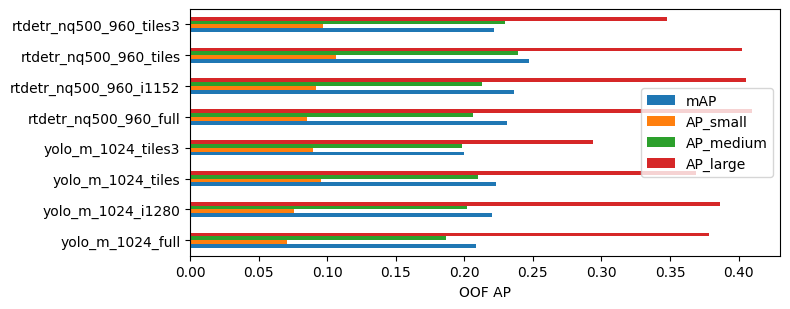

In [6]:
MAIN = ["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR500"]
table = {}
for n in VARIANTS:
    if not all((PRED_DIR / f"{n}_fold{k}_oof.parquet").exists() for k in range(common.N_FOLDS)):
        continue
    pf = {k: pd.read_parquet(PRED_DIR / f"{n}_fold{k}_oof.parquet") for k in range(common.N_FOLDS)}
    table[n] = common.evaluate_oof(pf, images, anns, splits, common.EVAL_STRIDE)
summ = pd.DataFrame({n: {**m.loc["oof", MAIN].to_dict(),
                         "mAP folds": m.loc[[0, 1, 2], "mAP"].round(4).tolist()} for n, m in table.items()}).T
display(summ)
fig, ax = plt.subplots(figsize=(8, 3.2))
pd.DataFrame({n: m.loc["oof", ["mAP", "AP_small", "AP_medium", "AP_large"]] for n, m in table.items()}).T.plot.barh(ax=ax)
ax.set_xlabel("OOF AP"); fig.tight_layout(); fig.savefig(IMG_DIR / "07_inference.png"); plt.show()

**Observations (test-time resolution, tiling):**
- **2×2 tiles help both models:** RT-DETR 0.231 → 0.248, YOLOv8m 0.208 → 0.223 (+7%), on every fold. The gain comes from small objects (AP_small +24% / +36%), while AP_large drops a little because large objects are cut by tile borders.
- **Simply feeding a larger frame helps less** (+2% RT-DETR at 1152 px, +6% YOLOv8m at 1280 px): tiles enlarge objects more (×1.67) at the training input size.
- **3×3 tiles are worse than 2×2** for all sizes (RT-DETR 0.222, YOLOv8m 0.200): ×2.5 enlargement is too far from the object scale seen in training, and AP_large falls by 15–22% vs the full frame. There is an optimum, and 2×2 is closer to it.
- Only the 2×2 variants pass the OOF rule and are used in the ensemble, where their small-object strength complements the full-frame predictions.

## 6. Logging

In [7]:
logged = WORK / ("logged07_quick" if QUICK else "logged07")
if not logged.exists():
    for n, m in table.items():
        base, kind, isz = VARIANTS[n]
        if kind == "full" and isz == BASES[base]["imgsz"]:
            continue   # the reference equals the experiment already logged by its training notebook
        common.log_results(m, RESULTS, owner="B", model=BASES[base]["model"], experiment=n, train_stride=20,
                           eval_stride=10, imgsz=isz, epochs=12,
                           notes=f"{base} fold models, inference: "
                                 + (f"{GRIDS[kind][0]}x{GRIDS[kind][0]} tiles" if kind in GRIDS else "full frame")
                                 + f" at {isz} px")
    logged.touch()
if RESULTS.exists():
    print(pd.read_csv(RESULTS).query("fold == 'oof'")[["experiment", "mAP", "AP_small", "AP_large"]])

                 experiment     mAP  AP_small  AP_large
5         yolo_m_1024_i1280  0.2200    0.0761    0.3862
11        yolo_m_1024_tiles  0.2233    0.0958    0.3689
17       yolo_m_1024_tiles3  0.1995    0.0895    0.2941
23   rtdetr_nq500_960_i1152  0.2363    0.0920    0.4055
29   rtdetr_nq500_960_tiles  0.2475    0.1064    0.4024
35  rtdetr_nq500_960_tiles3  0.2217    0.0971    0.3480


## 7. Test predictions of the useful variants
`TEST = "auto"`: a tiled variant is kept if its OOF mAP is above its reference or its AP_small is
more than 5 % above it (a tiles-only prediction can lose large objects and still add small ones to
the ensemble); the 3 x 3 grid is kept only if it also beats the 2 x 2 grid in AP_small. The
larger-input variants are evaluated for the comparison but not predicted on test: tiles enlarge the
objects more and are the better of the two on both models.

In [8]:
def reference(n):
    base = VARIANTS[n][0]
    return next(r for r, v in VARIANTS.items() if v[0] == base and v[1] == "full" and v[2] == BASES[base]["imgsz"])

def passes(n):
    r = reference(n)
    return r in table and (table[n].at["oof", "mAP"] > table[r].at["oof", "mAP"]
                           or table[n].at["oof", "AP_small"] > 1.05 * table[r].at["oof", "AP_small"])

if TEST == "auto":
    chosen = []
    for base in BASES:
        t2, t3 = f"{base}_tiles", f"{base}_tiles3"
        if t2 in table and passes(t2):
            chosen.append(t2)
        if t3 in table and passes(t3) and (t2 not in table or table[t3].at["oof", "AP_small"] > table[t2].at["oof", "AP_small"]):
            chosen.append(t3)
else:
    chosen = [] if TEST == "none" else list(TEST)
print("test predictions for:", chosen)
for base in HAVE:
    for k in range(common.N_FOLDS):
        todo = [n for n in chosen if VARIANTS[n][0] == base and not (PRED_DIR / f"{n}_fold{k}_test.parquet").exists()]
        if not todo:
            continue
        model = fold_model(base, k)
        for n in todo:
            t0 = time.time()
            p = run_variant(model, n, test, "image_id", base_cfg(base))
            p.to_parquet(PRED_DIR / f"{n}_fold{k}_test.parquet")
            print(f"{n} fold {k}: {len(test)} test frames, {(time.time() - t0) / 60:.1f} min", flush=True)
        del model; torch.cuda.empty_cache()
for n in VARIANTS:   # keep only what 06_ensemble can use: variants with test predictions
    if n not in chosen:
        for f in PRED_DIR.glob(f"{n}_fold*_oof.parquet"):
            f.rename(WORK / f"unused_{f.name}")
shutil.rmtree(RUN_ROOT, ignore_errors=True)   # the weights live in their training notebooks

test predictions for: ['yolo_m_1024_tiles', 'rtdetr_nq500_960_tiles']


## 8. Conclusions
Slicing-aided inference (2×2 tiles, no retraining) is the best inference-time change: +7% for each model and +9% for the ensemble (0.255 → 0.279 OOF). The improvement is limited by the scale shift between training and inference, which is why 3×3 tiles lose. The next step would be to train on crops so that training and tiled inference see the same object scale.